# LAB 2 – Khai phá dữ liệu: Bài tập thêm, câu 2 (Trang 32)
## Tính giá trị F-measure của các bài tập cơ bản

**Sinh viên:** Nguyễn Khánh Hà – 6451071022

**Đề bài (trang 32):** F-measure là trung bình điều hòa của độ chính xác (precision) và độ phủ (recall):

$$F\text{-}measure = 2 \times \frac{precision \times recall}{precision + recall}$$

Hãy tính giá trị F-measure của các bài tập cơ bản. Sinh viên có thể lập trình để cho ra kết quả.

**Các bài tập cơ bản trong đề (3 bài):**
1. **Yêu cầu cơ bản** (mục III.1, trang 1–15): đánh giá rủi ro hồ sơ vay tín dụng.
2. **Bài 1 (Cơ bản)** (mục IV, trang 23–25): dự đoán doanh số đồ chơi.
3. **Bài 2 (Cơ bản)** (mục IV, trang 25–26): phân tích cảm xúc.

**Cách làm (bám sát cách giải trong đề):**
- Cây **ID3**: chọn thuộc tính có độ lợi thông tin (information gain) lớn nhất, chia đa nhánh.
- Cây **CART**: chọn thuộc tính có chỉ số Gini nhỏ nhất, chia đa nhánh như ví dụ trong đề. Khi hai thuộc tính bằng nhau thì chọn thuộc tính đứng sau (như đề đã chọn *Sở hữu nhà* khi Gini ngang *Thu nhập*).
- **Naïve Bayes** làm trơn Laplace cho cả xác suất tiên nghiệm và xác suất có điều kiện, ví dụ $(6+1)/(9+2)$ và $10/17$ trong đề.
- Với mỗi bài: kiểm tra mẫu thuẫn → tính Gain/Gini → dựng cây → dự đoán → ma trận nhầm lẫn → precision, recall, F-measure.

## Chuẩn bị: thư viện và các hàm dùng chung

In [1]:
print("Nguyễn Khánh Hà - 6451071022")
import math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Độ đo ----------
def entropy(y):
    n = len(y)
    return -sum(k / n * math.log2(k / n) for k in Counter(y).values())

def gini(y):
    n = len(y)
    return 1 - sum((k / n) ** 2 for k in Counter(y).values())

def majority(y):
    return Counter(y).most_common(1)[0][0]

def info_gain(df, a, t):
    """Gain(S, A) = Entropy(S) - sum(|Sv|/|S| * Entropy(Sv))"""
    return entropy(list(df[t])) - sum(len(g) / len(df) * entropy(list(g[t])) for _, g in df.groupby(a))

def gini_index(df, a, t):
    """Gini_A(S) = sum(|Sv|/|S| * Gini(Sv))"""
    return sum(len(g) / len(df) * gini(list(g[t])) for _, g in df.groupby(a))

# ---------- Cây quyết định đa nhánh ----------
def build_tree(df, t, attrs, kind):
    """kind = 'id3' (Gain lớn nhất, hòa thì lấy thuộc tính đứng trước)
              'cart' (Gini nhỏ nhất, hòa thì lấy thuộc tính đứng sau - như đề)"""
    y = list(df[t])
    if len(set(y)) == 1 or not attrs:
        return {"leaf": majority(y)}
    if kind == "id3":
        score = {a: round(info_gain(df, a, t), 9) for a in attrs}
        best = max(score.values()); chon = [a for a in attrs if score[a] == best][0]
    else:
        score = {a: round(gini_index(df, a, t), 9) for a in attrs}
        best = min(score.values()); chon = [a for a in attrs if score[a] == best][-1]
    rest = [a for a in attrs if a != chon]
    return {"attr": chon, "maj": majority(y),
            "children": {v: build_tree(g, t, rest, kind) for v, g in df.groupby(chon)}}

def predict_tree(node, row):
    while "leaf" not in node:
        v = row[node["attr"]]
        if v not in node["children"]:          # giá trị chưa gặp -> lớp đa số tại nút
            return node["maj"]
        node = node["children"][v]
    return node["leaf"]

def show_tree(n, ind=""):
    if "leaf" in n:
        print(ind + "=> " + str(n["leaf"])); return
    for v, c in n["children"].items():
        print(f"{ind}[{n['attr']} = {v}]"); show_tree(c, ind + "      ")

# ---------- Naïve Bayes làm trơn Laplace (cả xác suất tiên nghiệm) ----------
def nb_train(df, t):
    attrs = [a for a in df.columns if a != t]
    classes = sorted(df[t].unique())
    return {"t": t, "attrs": attrs, "classes": classes, "N": len(df),
            "n": {c: int((df[t] == c).sum()) for c in classes},
            "vals": {a: sorted(df[a].unique()) for a in attrs},
            "cnt": {c: {a: df[df[t] == c][a].value_counts().to_dict() for a in attrs} for c in classes}}

def nb_scores(m, row):
    K = len(m["classes"])
    out = {}
    for c in m["classes"]:
        s = (m["n"][c] + 1) / (m["N"] + K)                        # P(c), ví dụ 10/17
        for a in m["attrs"]:
            s *= (m["cnt"][c][a].get(row[a], 0) + 1) / (m["n"][c] + len(m["vals"][a]))   # ví dụ (6+1)/(9+2)
        out[c] = s
    return out

def nb_predict(m, row):
    sc = nb_scores(m, row)
    return max(m["classes"], key=lambda c: sc[c])

# ---------- Đánh giá: ma trận nhầm lẫn, precision, recall, F-measure ----------
def danh_gia(actual, pred, labels, title):
    cm = pd.DataFrame(0, index=labels, columns=labels)
    for a, p in zip(actual, pred):
        cm.loc[a, p] += 1
    print(f"===== {title} =====")
    print("Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán):")
    print(cm.to_string())
    rows = []
    for c in labels:
        tp = cm.loc[c, c]; fp = cm[c].sum() - tp; fn = cm.loc[c].sum() - tp
        pre = tp / (tp + fp) if tp + fp > 0 else 0.0        # precision = TP / (TP + FP)
        rec = tp / (tp + fn) if tp + fn > 0 else 0.0        # recall    = TP / (TP + FN)
        f = 2 * pre * rec / (pre + rec) if pre + rec > 0 else 0.0
        rows.append({"Lớp dương": c, "TP": tp, "FP": fp, "FN": fn,
                     "Precision": round(pre, 4), "Recall": round(rec, 4), "F-measure": round(f, 4)})
    res = pd.DataFrame(rows).set_index("Lớp dương")
    acc = np.trace(cm.values) / cm.values.sum()
    print("\n" + res.to_string())
    print(f"\nAccuracy = {acc:.4f} | Macro-F-measure (trung bình các lớp) = {res['F-measure'].mean():.4f}")
    fig, ax = plt.subplots(figsize=(3.6 + len(labels) * 0.4, 3.2))
    ax.imshow(cm.values, cmap="Greens")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, cm.values[i, j], ha="center", va="center")
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title(title)
    plt.tight_layout(); plt.show()
    return res, acc

tong_hop = []     # gom kết quả của cả 3 bài để so sánh ở phần tổng kết
print("Đã định nghĩa xong các hàm dùng chung")

Nguyễn Khánh Hà - 6451071022
Đã định nghĩa xong các hàm dùng chung


## Hàm giải trọn một bài (kiểm tra mâu thuẫn → Gain/Gini → cây → dự đoán → F-measure)

In [2]:
print("Nguyễn Khánh Hà - 6451071022")
def giai_bai(ten, df, t, test, thuc_te, lop_duong=None, mau_moi=None):
    attrs = [a for a in df.columns if a != t]
    labels = sorted(df[t].unique())
    print("=" * 78); print(ten); print("=" * 78)

    # Mâu thuẫn: các dòng giống hệt nhau về thuộc tính nhưng khác nhãn
    so_nhan = df.groupby(attrs)[t].nunique()
    print(f"[Mâu thuẫn] Số nhóm dòng mâu thuẫn: {int((so_nhan > 1).sum())}")

    # Độ lợi thông tin và chỉ số Gini ở nút gốc
    print(f"\nEntropy(S) = {entropy(list(df[t])):.4f} | Gini(S) = {gini(list(df[t])):.4f}")
    bang = pd.DataFrame({"Information Gain": {a: info_gain(df, a, t) for a in attrs},
                         "Gini index": {a: gini_index(df, a, t) for a in attrs}}).round(4)
    print(bang.to_string())
    print("=> Nút gốc ID3:", bang["Information Gain"].idxmax(), "| Nút gốc CART:", bang["Gini index"].idxmin())

    cay_id3 = build_tree(df, t, attrs, "id3")
    cay_cart = build_tree(df, t, attrs, "cart")
    print("\nCây ID3:"); show_tree(cay_id3)
    print("\nCây CART:"); show_tree(cay_cart)

    # Dự đoán
    nb = nb_train(df, t)
    kq = test.copy()
    kq["ID3"] = [predict_tree(cay_id3, r) for _, r in test.iterrows()]
    kq["CART"] = [predict_tree(cay_cart, r) for _, r in test.iterrows()]
    kq["Naive Bayes"] = [nb_predict(nb, r) for _, r in test.iterrows()]
    kq["Thực tế"] = thuc_te
    print("\nKết quả dự đoán:")
    print(kq.to_string())
    print("\nĐiểm Naïve Bayes (Laplace) của từng mẫu:")
    for i, (_, r) in enumerate(test.iterrows(), 1):
        print(f"  Mẫu {i}:", {c: round(v, 5) for c, v in nb_scores(nb, r).items()})

    # Ma trận nhầm lẫn và F-measure
    print()
    for mh in ["ID3", "CART", "Naive Bayes"]:
        res, acc = danh_gia(thuc_te, list(kq[mh]), labels, f"{mh} - {ten}")
        if lop_duong is not None:
            f_chinh = res.loc[lop_duong, "F-measure"]; ten_f = f"F-measure (lớp dương = {lop_duong})"
        else:
            f_chinh = res["F-measure"].mean(); ten_f = "F-measure (macro)"
        tong_hop.append({"Bài": ten, "Mô hình": mh, "Accuracy": round(acc, 4),
                         "Precision": round(res.loc[lop_duong, "Precision"], 4) if lop_duong else round(res["Precision"].mean(), 4),
                         "Recall": round(res.loc[lop_duong, "Recall"], 4) if lop_duong else round(res["Recall"].mean(), 4),
                         "F-measure": round(f_chinh, 4), "Cách tính": ten_f})
        print()

    if mau_moi is not None:
        print("Dự đoán mẫu mới:")
        mm = mau_moi.copy()
        mm["ID3"] = [predict_tree(cay_id3, r) for _, r in mau_moi.iterrows()]
        mm["CART"] = [predict_tree(cay_cart, r) for _, r in mau_moi.iterrows()]
        mm["Naive Bayes"] = [nb_predict(nb, r) for _, r in mau_moi.iterrows()]
        print(mm.to_string())

print("Đã định nghĩa hàm giải_bai")

Nguyễn Khánh Hà - 6451071022
Đã định nghĩa hàm giải_bai


# Phần 1 – Yêu cầu cơ bản: đánh giá rủi ro hồ sơ vay tín dụng (trang 1–15)
Lớp dương là *Rủi ro thấp*. Dữ liệu huấn luyện 15 hồ sơ; 3 hồ sơ cần dự đoán ở Yêu cầu 4, nguy cơ thực tế ở Yêu cầu 5 là *Rủi ro cao, Rủi ro thấp, Rủi ro thấp*.

In [3]:
print("Nguyễn Khánh Hà - 6451071022")
cot = ["Thu nhập", "Nghề nghiệp", "Tình trạng hôn nhân", "Sở hữu nhà", "Nguy cơ"]
du_lieu_vay = pd.DataFrame([
    ["Thấp", "Vận tải", "Độc thân", "Rồi", "Rủi ro cao"],
    ["Thấp", "Vận tải", "Độc thân", "Chưa", "Rủi ro cao"],
    ["Cao", "Vận tải", "Độc thân", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Độc thân", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Kinh doanh", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Kinh doanh", "Đã kết hôn", "Chưa", "Rủi ro cao"],
    ["Cao", "Kinh doanh", "Đã kết hôn", "Chưa", "Rủi ro thấp"],
    ["Thấp", "Truyền thông", "Độc thân", "Rồi", "Rủi ro cao"],
    ["Thấp", "Kinh doanh", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Thấp", "Truyền thông", "Đã kết hôn", "Chưa", "Rủi ro thấp"],
    ["Cao", "Truyền thông", "Độc thân", "Chưa", "Rủi ro thấp"],
    ["Cao", "Vận tải", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Độc thân", "Chưa", "Rủi ro cao"],
    ["Cao", "Kinh doanh", "Độc thân", "Rồi", "Rủi ro cao"]], columns=cot)

test_vay = pd.DataFrame([["Trung bình", "Vận tải", "Độc thân", "Rồi"],
                         ["Cao", "Truyền thông", "Độc thân", "Rồi"],
                         ["Thấp", "Vận tải", "Đã kết hôn", "Rồi"]], columns=cot[:-1])
thuc_te_vay = ["Rủi ro cao", "Rủi ro thấp", "Rủi ro thấp"]
print("Số hồ sơ huấn luyện:", len(du_lieu_vay), "|", du_lieu_vay["Nguy cơ"].value_counts().to_dict())
du_lieu_vay

Nguyễn Khánh Hà - 6451071022
Số hồ sơ huấn luyện: 15 | {'Rủi ro thấp': 9, 'Rủi ro cao': 6}


,Thu nhập,Nghề nghiệp,Tình trạng hôn nhân,Sở hữu nhà,Nguy cơ
0,Thấp,Vận tải,Độc thân,Rồi,Rủi ro cao
1,Thấp,Vận tải,Độc thân,Chưa,Rủi ro cao
2,Cao,Vận tải,Độc thân,Rồi,Rủi ro thấp
3,Trung bình,Truyền thông,Độc thân,Rồi,Rủi ro thấp
4,Trung bình,Kinh doanh,Đã kết hôn,Rồi,Rủi ro thấp
5,Trung bình,Kinh doanh,Đã kết hôn,Chưa,Rủi ro cao
6,Cao,Kinh doanh,Đã kết hôn,Chưa,Rủi ro thấp
7,Thấp,Truyền thông,Độc thân,Rồi,Rủi ro cao
8,Thấp,Kinh doanh,Đã kết hôn,Rồi,Rủi ro thấp
9,Trung bình,Truyền thông,Đã kết hôn,Rồi,Rủi ro thấp


Nguyễn Khánh Hà - 6451071022
Yêu cầu cơ bản (vay tín dụng)
[Mâu thuẫn] Số nhóm dòng mâu thuẫn: 0

Entropy(S) = 0.9710 | Gini(S) = 0.4800
                     Information Gain  Gini index
Thu nhập                       0.0830      0.4267
Nghề nghiệp                    0.0133      0.4711
Tình trạng hôn nhân            0.1858      0.3643
Sở hữu nhà                     0.0200      0.4667
=> Nút gốc ID3: Tình trạng hôn nhân | Nút gốc CART: Tình trạng hôn nhân

Cây ID3:
[Tình trạng hôn nhân = Đã kết hôn]
      [Thu nhập = Cao]
            => Rủi ro thấp
      [Thu nhập = Thấp]
            => Rủi ro thấp
      [Thu nhập = Trung bình]
            [Sở hữu nhà = Chưa]
                  => Rủi ro cao
            [Sở hữu nhà = Rồi]
                  => Rủi ro thấp
[Tình trạng hôn nhân = Độc thân]
      [Thu nhập = Cao]
            [Nghề nghiệp = Kinh doanh]
                  => Rủi ro cao
            [Nghề nghiệp = Truyền thông]
                  => Rủi ro thấp
            [Nghề nghiệp = Vận tải]


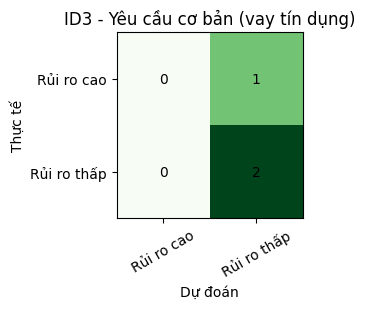


===== CART - Yêu cầu cơ bản (vay tín dụng) =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán):
             Rủi ro cao  Rủi ro thấp
Rủi ro cao            0            1
Rủi ro thấp           0            2

             TP  FP  FN  Precision  Recall  F-measure
Lớp dương                                            
Rủi ro cao    0   0   1     0.0000     0.0        0.0
Rủi ro thấp   2   1   0     0.6667     1.0        0.8

Accuracy = 0.6667 | Macro-F-measure (trung bình các lớp) = 0.4000


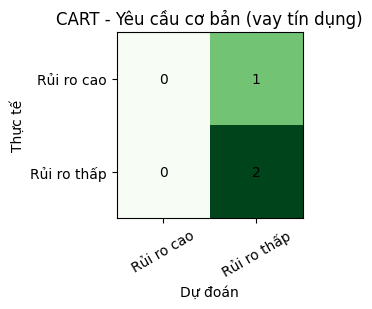


===== Naive Bayes - Yêu cầu cơ bản (vay tín dụng) =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán):
             Rủi ro cao  Rủi ro thấp
Rủi ro cao            1            0
Rủi ro thấp           0            2

             TP  FP  FN  Precision  Recall  F-measure
Lớp dương                                            
Rủi ro cao    1   0   0        1.0     1.0        1.0
Rủi ro thấp   2   0   0        1.0     1.0        1.0

Accuracy = 1.0000 | Macro-F-measure (trung bình các lớp) = 1.0000


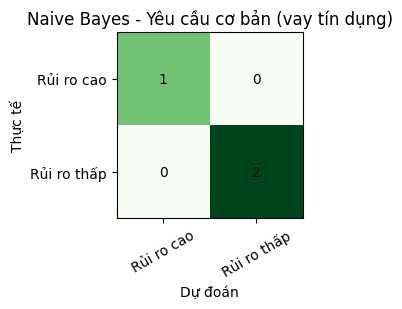

In [4]:
print("Nguyễn Khánh Hà - 6451071022")
giai_bai("Yêu cầu cơ bản (vay tín dụng)", du_lieu_vay, "Nguy cơ", test_vay, thuc_te_vay, lop_duong="Rủi ro thấp")

# Phần 2 – Bài 1 (Cơ bản): dự đoán doanh số đồ chơi (trang 23–25)
Đề không quy định lớp dương, chọn *Cao* làm lớp dương (đồng thời bảng ma trận nhầm lẫn in chỉ số cả hai lớp và F-measure macro để đối chiếu). 3 sản phẩm ở Yêu cầu d có doanh số thực tế *Thấp, Thấp, Cao* (Yêu cầu e); Yêu cầu l dự đoán sản phẩm mới.

In [5]:
print("Nguyễn Khánh Hà - 6451071022")
cot = ["Loại", "Số màu", "Kích thước", "Chất liệu", "Doanh số bán"]
du_lieu_dochoi = pd.DataFrame([
    ["Điều khiển", 3, "Nhỏ", "Nhựa PP", "Cao"], ["Xếp hình", 5, "Vừa", "Cao su", "Thấp"],
    ["Xếp hình", 7, "To", "Nhựa PP", "Thấp"],   ["Điều khiển", 5, "Nhỏ", "Cao su", "Thấp"],
    ["Búp bê", 3, "Vừa", "Nhựa PP", "Thấp"],    ["Điều khiển", 5, "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê", 5, "To", "Nhựa PP", "Cao"],      ["Điều khiển", 7, "Vừa", "Cao su", "Thấp"],
    ["Xếp hình", 7, "To", "Cao su", "Cao"],     ["Xếp hình", 3, "To", "Nhựa PP", "Thấp"],
    ["Búp bê", 3, "Nhỏ", "Cao su", "Thấp"],     ["Xếp hình", 3, "Nhỏ", "Nhựa PP", "Cao"],
    ["Điều khiển", 5, "To", "Cao su", "Thấp"],  ["Búp bê", 5, "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê", 7, "To", "Nhựa PP", "Cao"]], columns=cot).astype(str)   # xem "Số màu" là thuộc tính rời rạc

test_dochoi = pd.DataFrame([["Búp bê", 3, "To", "Cao su"], ["Xếp hình", 5, "To", "Nhựa PP"],
                            ["Điều khiển", 3, "Vừa", "Cao su"]], columns=cot[:-1]).astype(str)
thuc_te_dochoi = ["Thấp", "Thấp", "Cao"]
moi_dochoi = pd.DataFrame([["Xếp hình", 7, "Nhỏ", "Cao su"]], columns=cot[:-1]).astype(str)   # Yêu cầu l
print("Số mẫu huấn luyện:", len(du_lieu_dochoi), "|", du_lieu_dochoi["Doanh số bán"].value_counts().to_dict())
du_lieu_dochoi

Nguyễn Khánh Hà - 6451071022
Số mẫu huấn luyện: 15 | {'Thấp': 8, 'Cao': 7}


,Loại,Số màu,Kích thước,Chất liệu,Doanh số bán
0,Điều khiển,3,Nhỏ,Nhựa PP,Cao
1,Xếp hình,5,Vừa,Cao su,Thấp
2,Xếp hình,7,To,Nhựa PP,Thấp
3,Điều khiển,5,Nhỏ,Cao su,Thấp
4,Búp bê,3,Vừa,Nhựa PP,Thấp
5,Điều khiển,5,Vừa,Nhựa PP,Cao
6,Búp bê,5,To,Nhựa PP,Cao
7,Điều khiển,7,Vừa,Cao su,Thấp
8,Xếp hình,7,To,Cao su,Cao
9,Xếp hình,3,To,Nhựa PP,Thấp


Nguyễn Khánh Hà - 6451071022
Bài 1 (doanh số đồ chơi)
[Mâu thuẫn] Số nhóm dòng mâu thuẫn: 0

Entropy(S) = 0.9968 | Gini(S) = 0.4978
            Information Gain  Gini index
Loại                  0.0258      0.4800
Số màu                0.0065      0.4933
Kích thước            0.0065      0.4933
Chất liệu             0.1858      0.3778
=> Nút gốc ID3: Chất liệu | Nút gốc CART: Chất liệu

Cây ID3:
[Chất liệu = Cao su]
      [Loại = Búp bê]
            => Thấp
      [Loại = Xếp hình]
            [Số màu = 5]
                  => Thấp
            [Số màu = 7]
                  => Cao
      [Loại = Điều khiển]
            => Thấp
[Chất liệu = Nhựa PP]
      [Loại = Búp bê]
            [Số màu = 3]
                  => Thấp
            [Số màu = 5]
                  => Cao
            [Số màu = 7]
                  => Cao
      [Loại = Xếp hình]
            [Kích thước = Nhỏ]
                  => Cao
            [Kích thước = To]
                  => Thấp
      [Loại = Điều khiển]
          

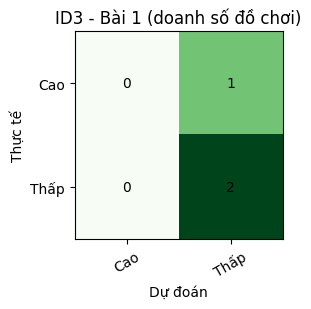


===== CART - Bài 1 (doanh số đồ chơi) =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán):
      Cao  Thấp
Cao     0     1
Thấp    1     1

           TP  FP  FN  Precision  Recall  F-measure
Lớp dương                                          
Cao         0   1   1        0.0     0.0        0.0
Thấp        1   1   1        0.5     0.5        0.5

Accuracy = 0.3333 | Macro-F-measure (trung bình các lớp) = 0.2500


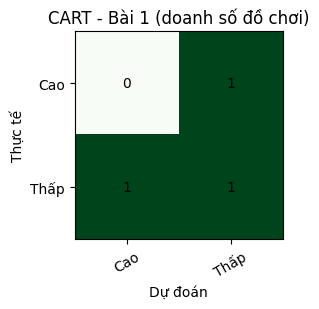


===== Naive Bayes - Bài 1 (doanh số đồ chơi) =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán):
      Cao  Thấp
Cao     0     1
Thấp    1     1

           TP  FP  FN  Precision  Recall  F-measure
Lớp dương                                          
Cao         0   1   1        0.0     0.0        0.0
Thấp        1   1   1        0.5     0.5        0.5

Accuracy = 0.3333 | Macro-F-measure (trung bình các lớp) = 0.2500


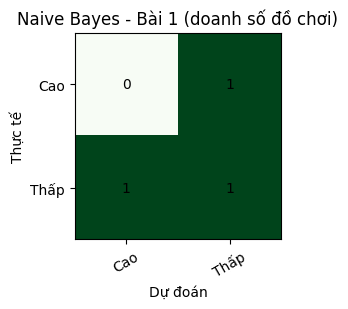


Dự đoán mẫu mới:
       Loại Số màu Kích thước Chất liệu  ID3  CART Naive Bayes
0  Xếp hình      7        Nhỏ    Cao su  Cao  Thấp        Thấp


In [6]:
print("Nguyễn Khánh Hà - 6451071022")
giai_bai("Bài 1 (doanh số đồ chơi)", du_lieu_dochoi, "Doanh số bán", test_dochoi, thuc_te_dochoi,
         lop_duong="Cao", mau_moi=moi_dochoi)

# Phần 3 – Bài 2 (Cơ bản): phân tích cảm xúc (trang 25–26)
Bài có 3 lớp nên tính F-measure cho từng lớp rồi lấy trung bình macro. 4 trạng thái ở Yêu cầu c có cảm xúc thực tế *xấu, tốt, bình thường, tốt* (Yêu cầu d).

In [7]:
print("Nguyễn Khánh Hà - 6451071022")
cot = ["giảm", "người", "chuyến", "yêu", "vừa", "đi", "Cảm xúc"]
du_lieu_cx = pd.DataFrame([
    ["0..5", "11..20", ">20", "11..20", ">20", "0..5", "tốt"],
    ["11..20", "6..10", "6..10", "0..5", "11..20", "11..20", "tốt"],
    ["6..10", "0..5", "6..10", "11..20", "0..5", "6..10", "xấu"],
    [">20", "0..5", "11..20", "6..10", "0..5", ">20", "bình thường"],
    ["0..5", ">20", "11..20", "0..5", "6..10", "0..5", "xấu"],
    ["0..5", "6..10", "0..5", "0..5", "11..20", "11..20", "xấu"],
    ["0..5", "6..10", "11..20", "0..5", "6..10", "0..5", "tốt"],
    ["11..20", ">20", "0..5", "11..20", "0..5", "11..20", "bình thường"],
    ["0..5", "0..5", "6..10", "6..10", "6..10", ">20", "tốt"],
    ["11..20", "0..5", "11..20", "11..20", "0..5", "11..20", "tốt"],
    [">20", "6..10", "0..5", "0..5", "0..5", "6..10", "xấu"],
    ["0..5", "0..5", "11..20", "0..5", "11..20", ">20", "bình thường"],
    ["6..10", "11..20", "6..10", ">20", "0..5", "6..10", "bình thường"],
    ["11..20", "6..10", ">20", "11..20", "0..5", "0..5", "xấu"]], columns=cot)

test_cx = pd.DataFrame([["0..5", "6..10", "0..5", "11..20", "6..10", "0..5"],
                        ["0..5", "0..5", "6..10", "0..5", "11..20", ">20"],
                        ["6..10", "0..5", "11..20", ">20", "6..10", "6..10"],
                        ["6..10", "11..20", "6..10", "6..10", ">20", "0..5"]], columns=cot[:-1])
thuc_te_cx = ["xấu", "tốt", "bình thường", "tốt"]
print("Số mẫu huấn luyện:", len(du_lieu_cx), "|", du_lieu_cx["Cảm xúc"].value_counts().to_dict())
du_lieu_cx

Nguyễn Khánh Hà - 6451071022
Số mẫu huấn luyện: 14 | {'tốt': 5, 'xấu': 5, 'bình thường': 4}


,giảm,người,chuyến,yêu,vừa,đi,Cảm xúc
0,0..5,11..20,>20,11..20,>20,0..5,tốt
1,11..20,6..10,6..10,0..5,11..20,11..20,tốt
2,6..10,0..5,6..10,11..20,0..5,6..10,xấu
3,>20,0..5,11..20,6..10,0..5,>20,bình thường
4,0..5,>20,11..20,0..5,6..10,0..5,xấu
5,0..5,6..10,0..5,0..5,11..20,11..20,xấu
6,0..5,6..10,11..20,0..5,6..10,0..5,tốt
7,11..20,>20,0..5,11..20,0..5,11..20,bình thường
8,0..5,0..5,6..10,6..10,6..10,>20,tốt
9,11..20,0..5,11..20,11..20,0..5,11..20,tốt


Nguyễn Khánh Hà - 6451071022
Bài 2 (phân tích cảm xúc)
[Mâu thuẫn] Số nhóm dòng mâu thuẫn: 0

Entropy(S) = 1.5774 | Gini(S) = 0.6633
        Information Gain  Gini index
giảm              0.2378      0.5833
người             0.4014      0.5429
chuyến            0.2657      0.5738
yêu               0.2657      0.5619
vừa               0.3166      0.5442
đi                0.4696      0.5119
=> Nút gốc ID3: đi | Nút gốc CART: đi

Cây ID3:
[đi = 0..5]
      [người = 11..20]
            => tốt
      [người = 6..10]
            [giảm = 0..5]
                  => tốt
            [giảm = 11..20]
                  => xấu
      [người = >20]
            => xấu
[đi = 11..20]
      [người = 0..5]
            => tốt
      [người = 6..10]
            [giảm = 0..5]
                  => xấu
            [giảm = 11..20]
                  => tốt
      [người = >20]
            => bình thường
[đi = 6..10]
      [người = 0..5]
            => xấu
      [người = 11..20]
            => bình thường
      [ngườ

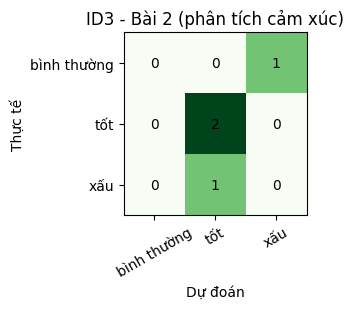


===== CART - Bài 2 (phân tích cảm xúc) =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán):
             bình thường  tốt  xấu
bình thường            1    0    0
tốt                    1    1    0
xấu                    0    1    0

             TP  FP  FN  Precision  Recall  F-measure
Lớp dương                                            
bình thường   1   1   0        0.5     1.0     0.6667
tốt           1   1   1        0.5     0.5     0.5000
xấu           0   0   1        0.0     0.0     0.0000

Accuracy = 0.5000 | Macro-F-measure (trung bình các lớp) = 0.3889


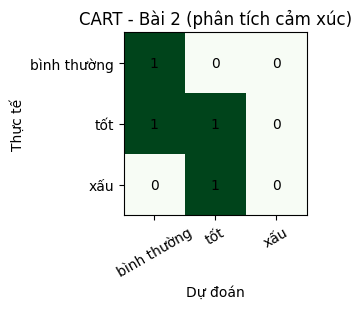


===== Naive Bayes - Bài 2 (phân tích cảm xúc) =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán):
             bình thường  tốt  xấu
bình thường            1    0    0
tốt                    0    2    0
xấu                    0    0    1

             TP  FP  FN  Precision  Recall  F-measure
Lớp dương                                            
bình thường   1   0   0        1.0     1.0        1.0
tốt           2   0   0        1.0     1.0        1.0
xấu           1   0   0        1.0     1.0        1.0

Accuracy = 1.0000 | Macro-F-measure (trung bình các lớp) = 1.0000


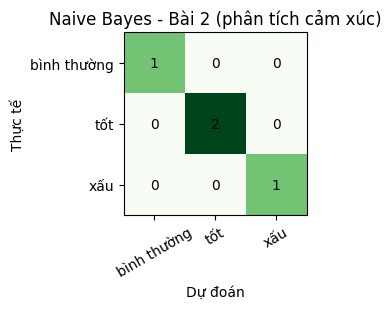

In [8]:
print("Nguyễn Khánh Hà - 6451071022")
giai_bai("Bài 2 (phân tích cảm xúc)", du_lieu_cx, "Cảm xúc", test_cx, thuc_te_cx, lop_duong=None)

# Tổng hợp F-measure của các bài tập cơ bản

Nguyễn Khánh Hà - 6451071022
                          Bài     Mô hình  Accuracy  Precision  Recall  F-measure                           Cách tính
Yêu cầu cơ bản (vay tín dụng)         ID3    0.6667     0.6667  1.0000     0.8000 F-measure (lớp dương = Rủi ro thấp)
Yêu cầu cơ bản (vay tín dụng)        CART    0.6667     0.6667  1.0000     0.8000 F-measure (lớp dương = Rủi ro thấp)
Yêu cầu cơ bản (vay tín dụng) Naive Bayes    1.0000     1.0000  1.0000     1.0000 F-measure (lớp dương = Rủi ro thấp)
     Bài 1 (doanh số đồ chơi)         ID3    0.6667     0.0000  0.0000     0.0000         F-measure (lớp dương = Cao)
     Bài 1 (doanh số đồ chơi)        CART    0.3333     0.0000  0.0000     0.0000         F-measure (lớp dương = Cao)
     Bài 1 (doanh số đồ chơi) Naive Bayes    0.3333     0.0000  0.0000     0.0000         F-measure (lớp dương = Cao)
    Bài 2 (phân tích cảm xúc)         ID3    0.5000     0.2222  0.3333     0.2667                   F-measure (macro)
    Bài 2 (phân tích cảm xú

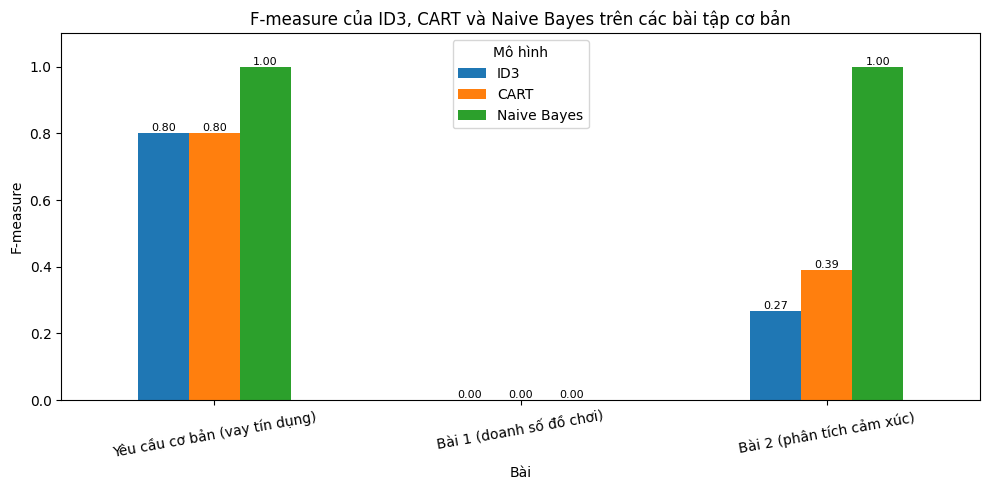

In [9]:
print("Nguyễn Khánh Hà - 6451071022")
bang_f = pd.DataFrame(tong_hop)
print(bang_f.to_string(index=False))

pivot = bang_f.pivot(index="Bài", columns="Mô hình", values="F-measure")[["ID3", "CART", "Naive Bayes"]]
pivot = pivot.loc[bang_f["Bài"].unique()]
ax = pivot.plot(kind="bar", figsize=(10, 5), rot=10)
plt.title("F-measure của ID3, CART và Naive Bayes trên các bài tập cơ bản")
plt.ylabel("F-measure"); plt.ylim(0, 1.1)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.show()

**Nhận xét:** Yêu cầu cơ bản (vay tín dụng, lớp dương = Rủi ro thấp): ID3 và CART cho cùng kết quả (precision 0.6667, recall 1.0, F-measure 0.8), trùng với số liệu 67% và 100% trong đề; Naïve Bayes (Laplace) dự đoán đúng cả 3 hồ sơ nên precision = recall = F-measure = 1.0, nghĩa là tốt hơn cây quyết định, đúng như kết luận ở Yêu cầu 11 của đề. Bài 1 (doanh số đồ chơi, lớp dương = Cao): không mô hình nào dự đoán đúng sản phẩm có doanh số Cao nên F-measure lớp Cao của cả ba mô hình đều bằng 0; xét lớp Thấp thì ID3 đạt F-measure 0.8 (Macro-F 0.4), còn CART và Naïve Bayes đạt 0.5 (Macro-F 0.25). Bài 2 (phân tích cảm xúc, 3 lớp, trung bình macro): Naïve Bayes dự đoán đúng cả 4 mẫu nên F-measure = 1.0, cây CART đạt 0.3889 và cây ID3 đạt 0.2667. Kết luận: Naïve Bayes có F-measure cao nhất ở 2 trong 3 bài cơ bản (riêng Bài 1 thì ID3 tốt hơn). Tuy nhiên tập kiểm thử chỉ có 3 đến 4 mẫu nên F-measure thay đổi rất lớn chỉ với một mẫu dự đoán sai, kết quả chỉ mang tính minh họa cách tính precision, recall và F-measure.